*The following lab was inspired in the work of Santiago Ríos Guiral (santiago.riosg@udea.edu.co), Santiago Taborda Echeverri (santiago.tabordae@udea.edu.co) and Brayan David Ramos Caicedo (brayan.ramos@udea.edu.co).*

# **Attack Classification**

In the following practice we will analyze the [UNSW-NB15](https://research.unsw.edu.au/projects/unsw-nb15-dataset) database. This database was generated with real and synthetic traffic. The .pcap files are available for its manipulation, however we will use a data set that contains per-flow characteristics of the aforementioned captures. If you want to check in detail how this database was constructed, you can check this [article](https://ieeexplore.ieee.org/abstract/document/7348942).

We will use per-flow generated features (a flow is an unidirectional sequence of packets that have some protocol-header values in common, for example, source and destination IP and ports). This is widely used in network traffic classification, since using per-packet features offer, in general, worse performances compared to its flow-based counterpart. An article explaining the differences between both type of features can be found [here](http://conferences.sigcomm.org/imc/2004/papers/p135-roughan.pdf).  

In [1]:
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1ar_NqHPZiYp9Zd7piZcNZkk-JskvWqwz' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1ar_NqHPZiYp9Zd7piZcNZkk-JskvWqwz" -O UNSW_NB15_complete-set.csv && rm -rf /tmp/cookies.txt
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1JA9YzlFWhiqOYg4in1YEsGgyeJQ5qmwt' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1JA9YzlFWhiqOYg4in1YEsGgyeJQ5qmwt" -O UNSW_NB15_training-set.csv && rm -rf /tmp/cookies.txt
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1aI_sXc3I8XMCmVSqCuEYXEpht_fseA1m' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1aI_sXc3I8XMCmVSqCuEYXEpht_fseA1m" -O UNSW_NB15_testing-set.csv && rm -rf /tmp/cookies.txt
!wget -nc --no-cache -O init.py -q https://raw.githubusercontent.com/rramosp/2021.deeplearning/main/content/init.py
import init; init.init(force_download=False);

--2026-08-10 21:29:18--  https://docs.google.com/uc?export=download&confirm=&id=1ar_NqHPZiYp9Zd7piZcNZkk-JskvWqwz
Resolving docs.google.com (docs.google.com)... 192.178.219.113, 192.178.219.101, 192.178.219.139, ...
Connecting to docs.google.com (docs.google.com)|192.178.219.113|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1ar_NqHPZiYp9Zd7piZcNZkk-JskvWqwz&export=download [following]
--2026-08-10 21:29:18--  https://drive.usercontent.google.com/download?id=1ar_NqHPZiYp9Zd7piZcNZkk-JskvWqwz&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 173.194.216.132, 2607:f8b0:400c:c12::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|173.194.216.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 49217462 (47M) [application/octet-stream]
Saving to: ‘UNSW_NB15_complete-set.csv’

UNSW_NB15_complete- 100%[=================

replicating local resources


In [2]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import scale

Let's import the dataset and check how it looks:

In [3]:
df_attack=pd.read_csv("/content/UNSW_NB15_complete-set.csv")
df_attack.tail()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
257668,82328,0.000005,udp,-,INT,2,0,104,0,200000.005100,...,1,2,0,0,0,2,1,0,Normal,0
257669,82329,1.106101,tcp,-,FIN,20,8,18062,354,24.410067,...,1,1,0,0,0,3,2,0,Normal,0
257670,82330,0.000000,arp,-,INT,1,0,46,0,0.000000,...,1,1,0,0,0,1,1,1,Normal,0
257671,82331,0.000000,arp,-,INT,1,0,46,0,0.000000,...,1,1,0,0,0,1,1,1,Normal,0
257672,82332,0.000009,udp,-,INT,2,0,104,0,111111.107200,...,1,1,0,0,0,1,1,0,Normal,0


Try to analize different characteristics of the dataset (size, number of samples per class, number of classes, feature types, measures of central tendency)

In [4]:
df_attack['attack_cat'].value_counts()

,count
attack_cat,
Normal,93000
Generic,58871
Exploits,44525
Fuzzers,24246
DoS,16353
Reconnaissance,13987
Analysis,2677
Backdoor,2329
Shellcode,1511


In [5]:
df_attack.dtypes

,0
id,int64
dur,float64
proto,object
service,object
state,object
spkts,int64
dpkts,int64
sbytes,int64
dbytes,int64
rate,float64


In [6]:
df_attack.shape

(257673, 45)

In [7]:
df_attack.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')

In [8]:
df_attack.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  si

In [9]:
df_attack.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,257673.000000,257673.000000,257673.000000,257673.000000,2.576730e+05,2.576730e+05,2.576730e+05,257673.000000,257673.000000,2.576730e+05,...,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000
mean,72811.823858,1.246715,19.777144,18.514703,8.572952e+03,1.438729e+04,9.125391e+04,180.000931,84.754957,7.060869e+07,...,5.238271,4.032677,8.322964,0.012819,0.012850,0.132005,6.800045,9.121049,0.014274,0.639077
std,48929.917641,5.974305,135.947152,111.985965,1.737739e+05,1.461993e+05,1.603446e+05,102.488268,112.762131,1.857313e+08,...,8.160822,5.831515,11.120754,0.116091,0.116421,0.681854,8.396266,10.874752,0.118618,0.480269
min,1.000000,0.000000,1.000000,0.000000,2.400000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,32210.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.078928e+01,62.000000,0.000000,1.231800e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,64419.000000,0.004285,4.000000,2.000000,5.280000e+02,1.780000e+02,2.955665e+03,254.000000,29.000000,7.439423e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,110923.000000,0.685777,12.000000,10.000000,1.362000e+03,1.064000e+03,1.250000e+05,254.000000,252.000000,8.000000e+07,...,4.000000,3.000000,8.000000,0.000000,0.000000,0.000000,8.000000,11.000000,0.000000,1.000000
max,175341.000000,59.999989,10646.000000,11018.000000,1.435577e+07,1.465753e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,59.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


A good practice is to check how disperse are the features, analyze its skewness and identify outliers. Boxplots are good tools to check this, try to select different features and plot them. Since we are dealing with different types of attacks, is recommended that you generate a boxplot per each feature related to each label. For example, if you want to analyze the feature *smean*, you should draw 10 boxplots (9 for all the attack types and 1 for the normal traffic). Draw your own conclusions.



In [10]:
training_DB = pd.read_csv("/content/UNSW_NB15_complete-set.csv", index_col=0)
df_analysis = pd.DataFrame({'dload':training_DB['dload'][:] , 'label': training_DB['label'][:]})
protos = list(training_DB['proto'].unique())
protos_dict = {}

for index, proto in enumerate (protos):
    protos_dict[proto] = index

training_DB_proto = training_DB.copy()
training_DB_proto = training_DB_proto.replace(protos_dict)
training_DB_proto['proto'].unique()

/tmp/ipykernel_1016/1008732291.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  training_DB_proto = training_DB_proto.replace(protos_dict)


array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132])

We recommend you to check the following features, however, you are free to choose and compare the variables you consider.

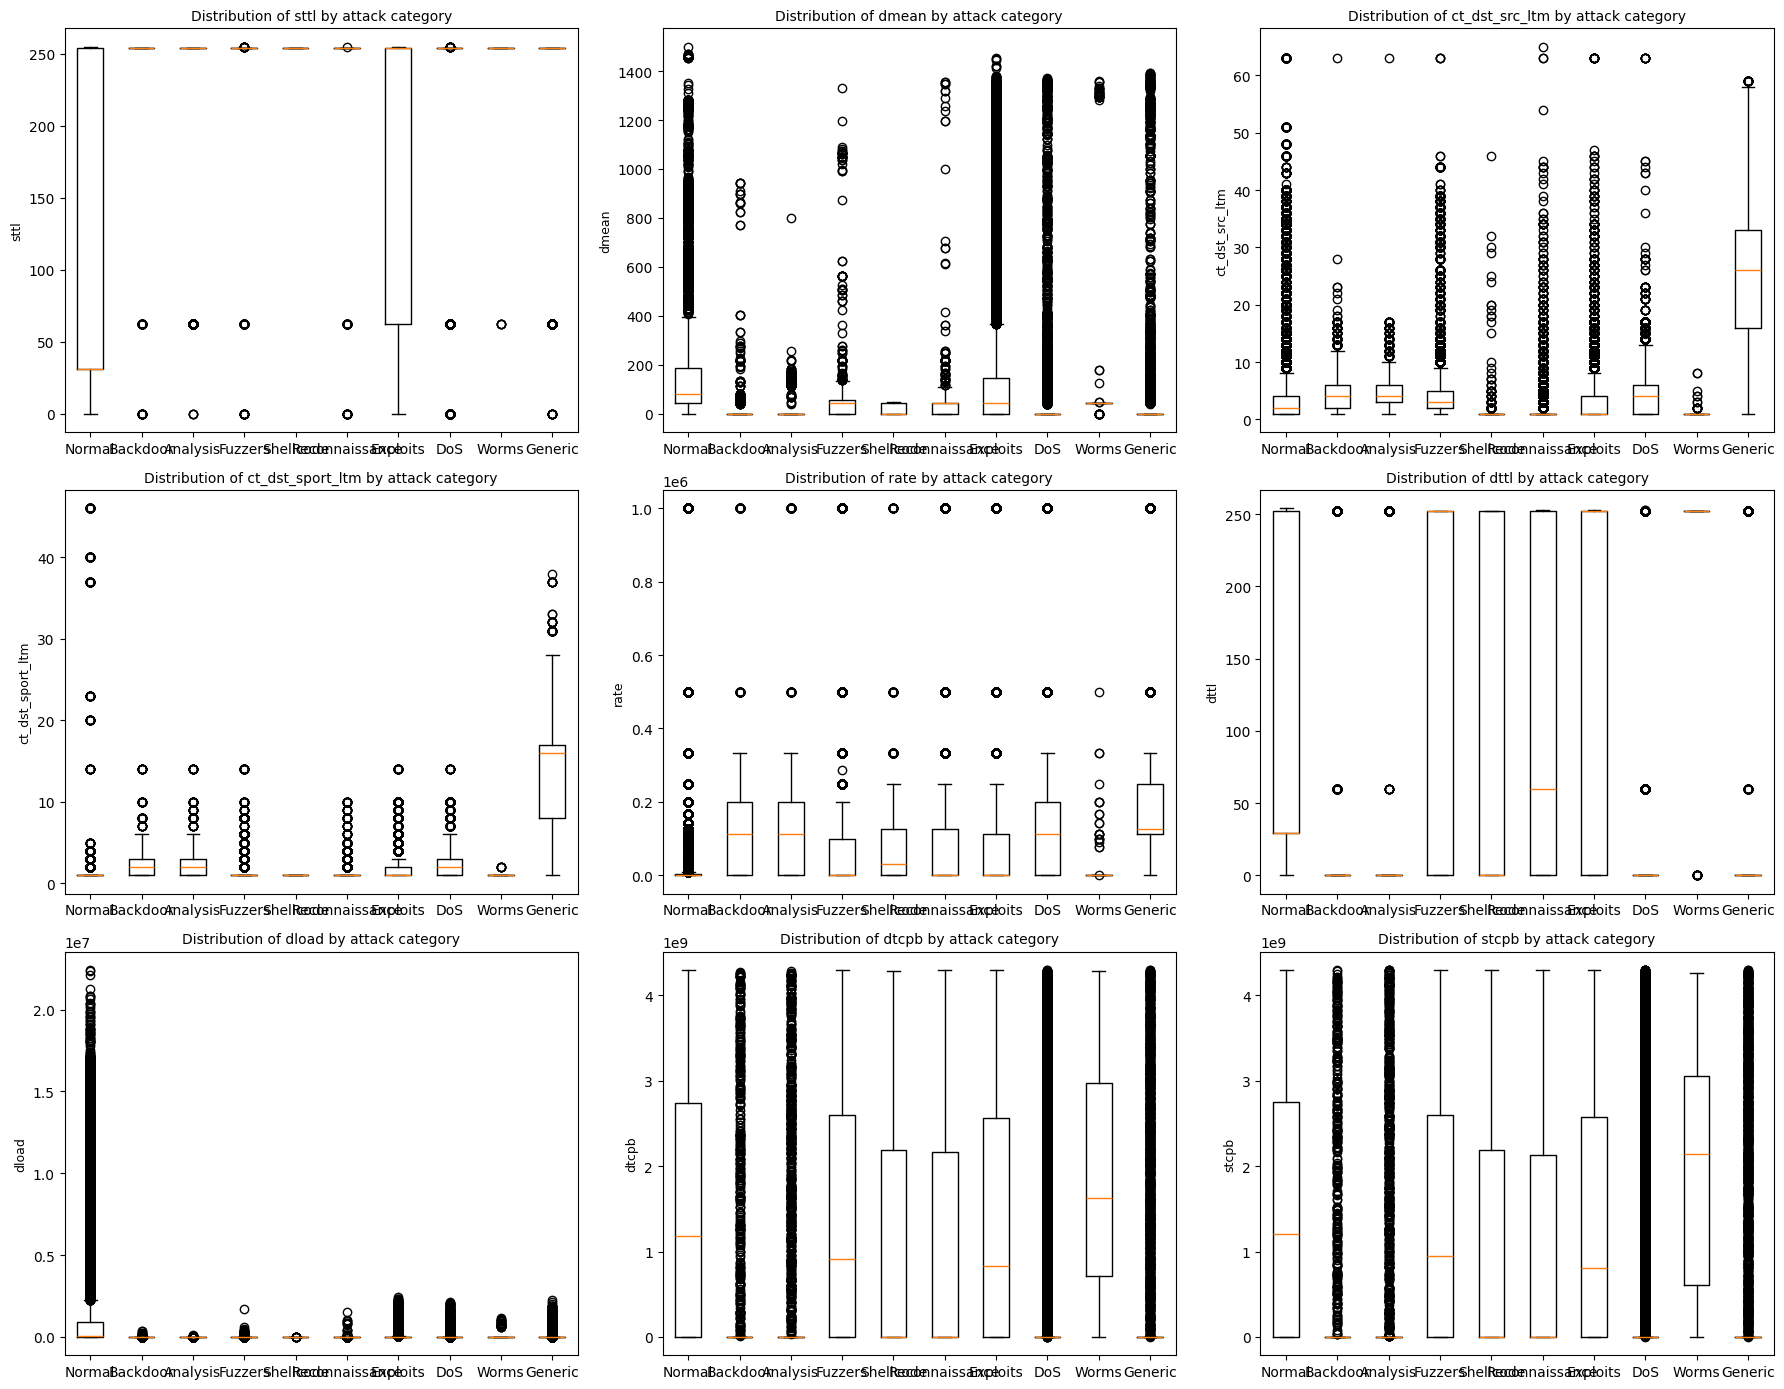

In [14]:
features1 = ['sttl','ct_dst_src_ltm','spkts','dload','sloss','dloss','ct_src_ltm','ct_srv_dst']
features2 = ['sbytes','sttl','smean','ct_dst_sport_ltm']
significant_features = ['proto','sttl','dmean','ct_dst_src_ltm','ct_dst_sport_ltm','rate','dttl','dload','dtcpb','stcpb']
feat = ['sttl','dmean','ct_dst_src_ltm','ct_dst_sport_ltm','rate','dttl','dload','dtcpb','stcpb']

# Boxplots: one figure per feature, with distributions split by attack category
attack_cats = df_attack['attack_cat'].unique()
n_cats = len(attack_cats)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 14))
axes = axes.flatten()

for idx, feature in enumerate(feat[:9]):
    data_to_plot = [df_attack[df_attack['attack_cat'] == cat][feature].dropna() for cat in attack_cats]
    bp = axes[idx].boxplot(data_to_plot, tick_labels=attack_cats)
    axes[idx].set_title(f'Distribution of {feature} by attack category', fontsize=10)
    axes[idx].set_ylabel(feature, fontsize=9)

plt.tight_layout()
plt.show()

We will try to analyze three different problems. First, we will try to solve a two-class problem, aiming to classify normal traffic and anomalous traffic. Here is important to have in mind that the samples that are labeled as "attack" come from different types of attacks (worms, DoS, Fuzzers, among others). Then we will pick a particular attack (e.g. DDoS) and try to differentiate it from normal traffic. Finally, we will solve a multi-class problem, where we will try to simultaneously classify several attacks.

Sometimes models trained on unbalanced datasets offer poor results when used to classify unseen samples. This is because some algorithms, when receiving more data from one particular class, could be biased towards that particular group of observations, failing to understand the patterns used to distinguish among classes and leading to overfitting the bigger class. Since there is more data from the majority class, the [accuracy paradox](https://medium.com/strands-tech-corner/unbalanced-datasets-what-to-do-144e0552d9cd) can be present, since you could get a model that assign the same class to all observations.

There are different alternatives to deal with this issue, in this case we will use undersampling, trying to reduce the ratio between classes, just selecting random observations without replacement. If you want to do an "informed" undersampling, you could use a clustering technique first to retain the most of the underlying information of each class.


In [15]:
df_attack['attack_cat'].value_counts()

,count
attack_cat,
Normal,93000
Generic,58871
Exploits,44525
Fuzzers,24246
DoS,16353
Reconnaissance,13987
Analysis,2677
Backdoor,2329
Shellcode,1511


In [16]:
df_attack['label'].value_counts()

,count
label,
1,164673
0,93000


The dataset contains some categorical variables, these features can be coded and used in some particular algorithms, if you want, you can drop these columns and solve the classification problem. Further work could be trying to codify these features and choosing an algorithm that fits.

In [17]:
df_attack_ub = df_attack.drop(columns=['id','proto','service','state'])
df_attack_ub.dtypes


,0
dur,float64
spkts,int64
dpkts,int64
sbytes,int64
dbytes,int64
rate,float64
sttl,int64
dttl,int64
sload,float64
dload,float64


In [18]:
df_attack_ub.head()

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,...,1,1,0,0,0,1,1,0,Normal,0
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,...,1,2,0,0,0,1,6,0,Normal,0
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,...,1,3,0,0,0,2,6,0,Normal,0
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,...,1,3,1,1,0,2,1,0,Normal,0
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,...,1,40,0,0,0,2,39,0,Normal,0


First, try to solve the two class classification problem between normal traffic (labeled as "0"), and attack samples (labeled as "1"). Here you can try to solve the problem with an unbalanced dataset and then check if there is any improvement working with a balanced dataset. We recommend you to use a 70-30 train-test split. Try to use at least two types of classifiers that can handle continuos and discrete features.

**2 Classes (normal and attack) - Unbalanced**

Train size: 180371, Test size: 77302
Train class distribution:
label
1    115271
0     65100
Name: count, dtype: int64
Test class distribution:
label
1    49402
0    27900
Name: count, dtype: int64

[Decision Tree] Accuracy (unbalanced): 0.9364


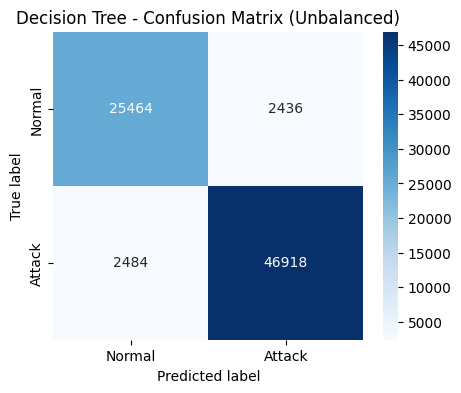


[KNN] Accuracy (unbalanced): 0.8528


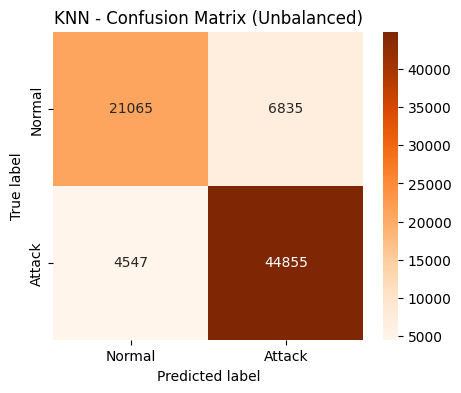

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare features (X) and labels (y) for binary classification
# Drop categorical columns and keep only numeric features
X = df_attack_ub.drop(columns=['attack_cat', 'label'])
y = df_attack_ub['label']  # 0 = normal, 1 = attack

# 70/30 stratified split
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train size: {len(x_train)}, Test size: {len(x_test)}")
print(f"Train class distribution:\n{y_train.value_counts()}")
print(f"Test class distribution:\n{y_test.value_counts()}")

# --- Classifier 1: Decision Tree ---
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(x_train, y_train)
y_pred_dt = dt_clf.predict(x_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"\n[Decision Tree] Accuracy (unbalanced): {acc_dt:.4f}")

cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('Decision Tree - Confusion Matrix (Unbalanced)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

# --- Classifier 2: K-Nearest Neighbors ---
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(x_train, y_train)
y_pred_knn = knn_clf.predict(x_test)
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"\n[KNN] Accuracy (unbalanced): {acc_knn:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('KNN - Confusion Matrix (Unbalanced)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

**2 Classes (normal and attack) - balanced**

Original train distribution: Counter({1: 115271, 0: 65100})
Resampled train distribution: Counter({0: 65100, 1: 65100})
Original test distribution: Counter({1: 49402, 0: 27900})
Resampled test distribution: Counter({0: 27900, 1: 27900})

[Decision Tree] Accuracy (balanced): 0.9322


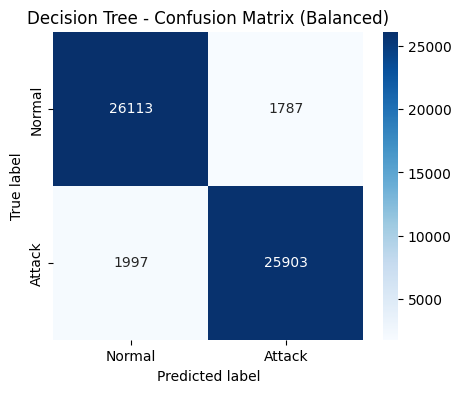


[KNN] Accuracy (balanced): 0.8300


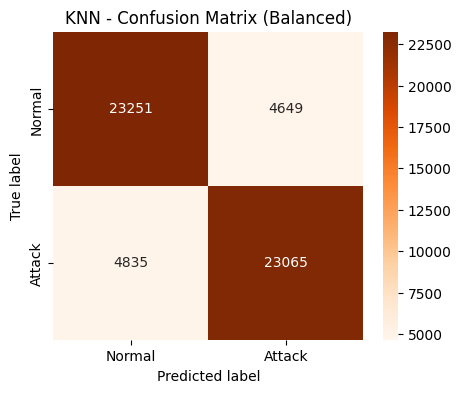

In [20]:
# Balanced classification using RandomUnderSampler
# Note: x_train, y_train, x_test, y_test come from the previous cell
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

# Undersample the training set
under_sampler = RandomUnderSampler(random_state=42)
x_res, y_res = under_sampler.fit_resample(x_train, y_train)
x_res_test, y_res_test = under_sampler.fit_resample(x_test, y_test)

print(f"Original train distribution: {Counter(y_train)}")
print(f"Resampled train distribution: {Counter(y_res)}")
print(f"Original test distribution: {Counter(y_test)}")
print(f"Resampled test distribution: {Counter(y_res_test)}")

# --- Decision Tree on balanced data ---
dt_bal = DecisionTreeClassifier(random_state=42)
dt_bal.fit(x_res, y_res)
y_pred_dt_bal = dt_bal.predict(x_res_test)
acc_dt_bal = accuracy_score(y_res_test, y_pred_dt_bal)
print(f"\n[Decision Tree] Accuracy (balanced): {acc_dt_bal:.4f}")

cm_dt_bal = confusion_matrix(y_res_test, y_pred_dt_bal)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt_bal, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('Decision Tree - Confusion Matrix (Balanced)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

# --- KNN on balanced data ---
knn_bal = KNeighborsClassifier(n_neighbors=5)
knn_bal.fit(x_res, y_res)
y_pred_knn_bal = knn_bal.predict(x_res_test)
acc_knn_bal = accuracy_score(y_res_test, y_pred_knn_bal)
print(f"\n[KNN] Accuracy (balanced): {acc_knn_bal:.4f}")

cm_knn_bal = confusion_matrix(y_res_test, y_pred_knn_bal)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn_bal, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('KNN - Confusion Matrix (Balanced)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

**2 Classes (normal and DDoS) - unbalanced**

In [21]:
df2_ub = df_attack_ub.loc[(df_attack_ub['attack_cat']=='Normal') | (df_attack_ub['attack_cat']=='DoS')]
df2_ub['attack_cat'].value_counts()

,count
attack_cat,
Normal,93000
DoS,16353


In [22]:
df2_ub.head()

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,...,1,1,0,0,0,1,1,0,Normal,0
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,...,1,2,0,0,0,1,6,0,Normal,0
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,...,1,3,0,0,0,2,6,0,Normal,0
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,...,1,3,1,1,0,2,1,0,Normal,0
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,...,1,40,0,0,0,2,39,0,Normal,0


**2 Classes (normal and DDoS) - balanced**




**Multiclass problem - unbalanced**

In [23]:
df_attack_ub = df_attack.drop(columns=['id','proto','service','state','label'])
att = {'Backdoor':0, 'Analysis':1, 'Fuzzers':2, 'Shellcode':3,'Reconnaissance':4, 'Exploits':5, 'DoS':6, 'Worms':7,'Generic':8, 'Normal':9}
df3_ub = df_attack_ub
df3_ub.replace({'attack_cat':att},inplace=True)

/tmp/ipykernel_1016/1461187924.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df3_ub.replace({'attack_cat':att},inplace=True)


In [24]:
df3_ub.head()

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,...,1,1,1,0,0,0,1,1,0,9
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,...,1,1,2,0,0,0,1,6,0,9
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,...,1,1,3,0,0,0,2,6,0,9
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,...,1,1,3,1,1,0,2,1,0,9
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,...,2,1,40,0,0,0,2,39,0,9


**Multiclass problem - balanced**

**Multiclass problem - balanced - removing classes with little data**

In [25]:
df3_ub['attack_cat'].value_counts()

,count
attack_cat,
9,93000
8,58871
5,44525
2,24246
6,16353
4,13987
1,2677
0,2329
3,1511


In [26]:
df_attack_ub = df_attack.drop(columns=['id','proto','service','state','label'])
df4_ub = df_attack_ub
df4_ub = df4_ub.loc[(df4_ub['attack_cat']!='Worms') & (df4_ub['attack_cat']!='Shellcode')& (df4_ub['attack_cat']!='Backdoor')& (df4_ub['attack_cat']!='Analysis')]

att = {'Backdoor':0, 'Analysis':1, 'Fuzzers':2, 'Shellcode':3,'Reconnaissance':4, 'Exploits':5, 'DoS':6, 'Worms':7,'Generic':8, 'Normal':9}
df4_ub.replace({'attack_cat':att},inplace=True)
df4_ub['attack_cat'].value_counts()

/tmp/ipykernel_1016/4068890411.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df4_ub.replace({'attack_cat':att},inplace=True)
/tmp/ipykernel_1016/4068890411.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4_ub.replace({'attack_cat':att},inplace=True)


,count
attack_cat,
9,93000
8,58871
5,44525
2,24246
6,16353
4,13987


Now, pick one of the previous problems and check the results choosing the features that you consider provide the most information. Check if there is any improvement in the accuracy.



Accuracy with 7 selected features: 0.9131
Previous accuracy with all features (Decision Tree): 0.9364
Difference: -0.0233


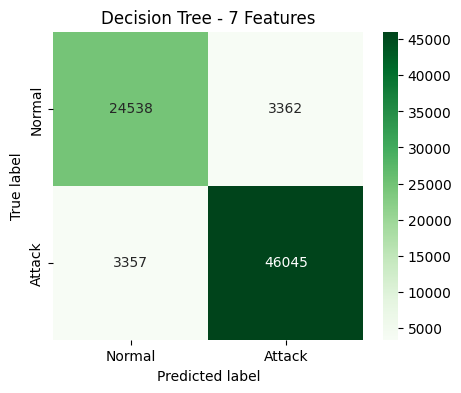

In [28]:
selected_features = ['sttl', 'dmean', 'rate', 'dload', 'sload', 'spkts', 'dpkts']
X_subset = X[selected_features]
y_subset = y

# 70/30 stratified split
x_tr_sub, x_te_sub, y_tr_sub, y_te_sub = train_test_split(
    X_subset, y_subset, test_size=0.3, random_state=42, stratify=y_subset
)

# Train Decision Tree on subset
dt_sub = DecisionTreeClassifier(random_state=42)
dt_sub.fit(x_tr_sub, y_tr_sub)
y_pred_sub = dt_sub.predict(x_te_sub)
acc_sub = accuracy_score(y_te_sub, y_pred_sub)

print(f"Accuracy with {len(selected_features)} selected features: {acc_sub:.4f}")
# The variable `acc_dt` was calculated in a previous cell and should still be available in the kernel.
print(f"Previous accuracy with all features (Decision Tree): {acc_dt:.4f}")
print(f"Difference: {acc_sub - acc_dt:+.4f}")

cm_sub = confusion_matrix(y_te_sub, y_pred_sub)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_sub, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title(f'Decision Tree - {len(selected_features)} Features')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

Finally read about data standarization. Check if you can apply it to any of the features. Again, draw your own conclusions.

In [29]:
# Data standardization experiment
# Apply StandardScaler to the selected features and re-run the classifier
from sklearn.preprocessing import StandardScaler

# Use the same subset as the feature selection cell
scaler = StandardScaler()
x_tr_scaled = scaler.fit_transform(x_tr_sub)
x_te_scaled = scaler.transform(x_te_sub)

# Train Decision Tree on standardized features
dt_scaled = DecisionTreeClassifier(random_state=42)
dt_scaled.fit(x_tr_scaled, y_tr_sub)
y_pred_scaled = dt_scaled.predict(x_te_scaled)
acc_scaled = accuracy_score(y_te_sub, y_pred_scaled)

print(f"Accuracy with standardization: {acc_scaled:.4f}")
print(f"Accuracy without standardization: {acc_sub:.4f}")
print(f"Difference: {acc_scaled - acc_sub:+.4f}")
print("\nConclusion: Decision trees are scale-invariant, so standardization")
print("should not change the accuracy significantly. Try with KNN to see a difference.")

# KNN with standardization
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(x_tr_scaled, y_tr_sub)
y_pred_knn_scaled = knn_scaled.predict(x_te_scaled)
acc_knn_scaled = accuracy_score(y_te_sub, y_pred_knn_scaled)

# KNN without standardization (using the subset)
knn_noscale = KNeighborsClassifier(n_neighbors=5)
knn_noscale.fit(x_tr_sub, y_tr_sub)
y_pred_knn_noscale = knn_noscale.predict(x_te_sub)
acc_knn_noscale = accuracy_score(y_te_sub, y_pred_knn_noscale)

print(f"\n[KNN] Accuracy with standardization:    {acc_knn_scaled:.4f}")
print(f"[KNN] Accuracy without standardization: {acc_knn_noscale:.4f}")
print(f"[KNN] Difference: {acc_knn_scaled - acc_knn_noscale:+.4f}")

Accuracy with standardization: 0.9141
Accuracy without standardization: 0.9131
Difference: +0.0011

Conclusion: Decision trees are scale-invariant, so standardization
should not change the accuracy significantly. Try with KNN to see a difference.

[KNN] Accuracy with standardization:    0.9143
[KNN] Accuracy without standardization: 0.8890
[KNN] Difference: +0.0253
